# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import MASATIImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/MASATI/image_classification/",
    "csv_file": "./data/MASATI/image_classification/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = MASATIImageClassificationDataset(dataset_config)

## Show images from the dataset

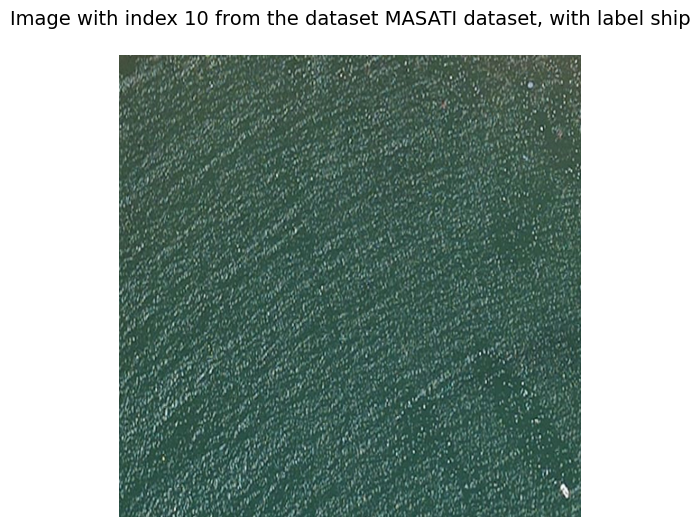

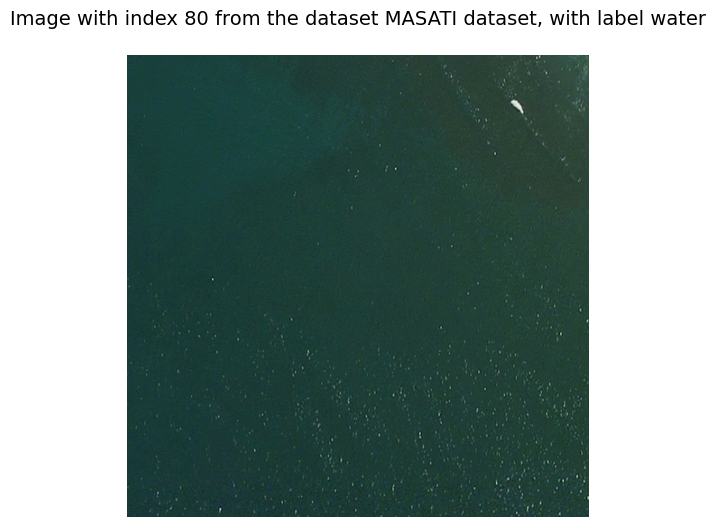

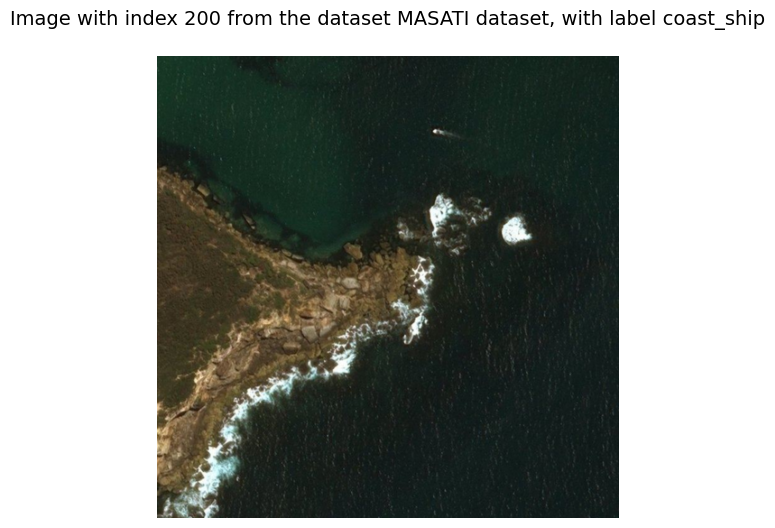

In [21]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

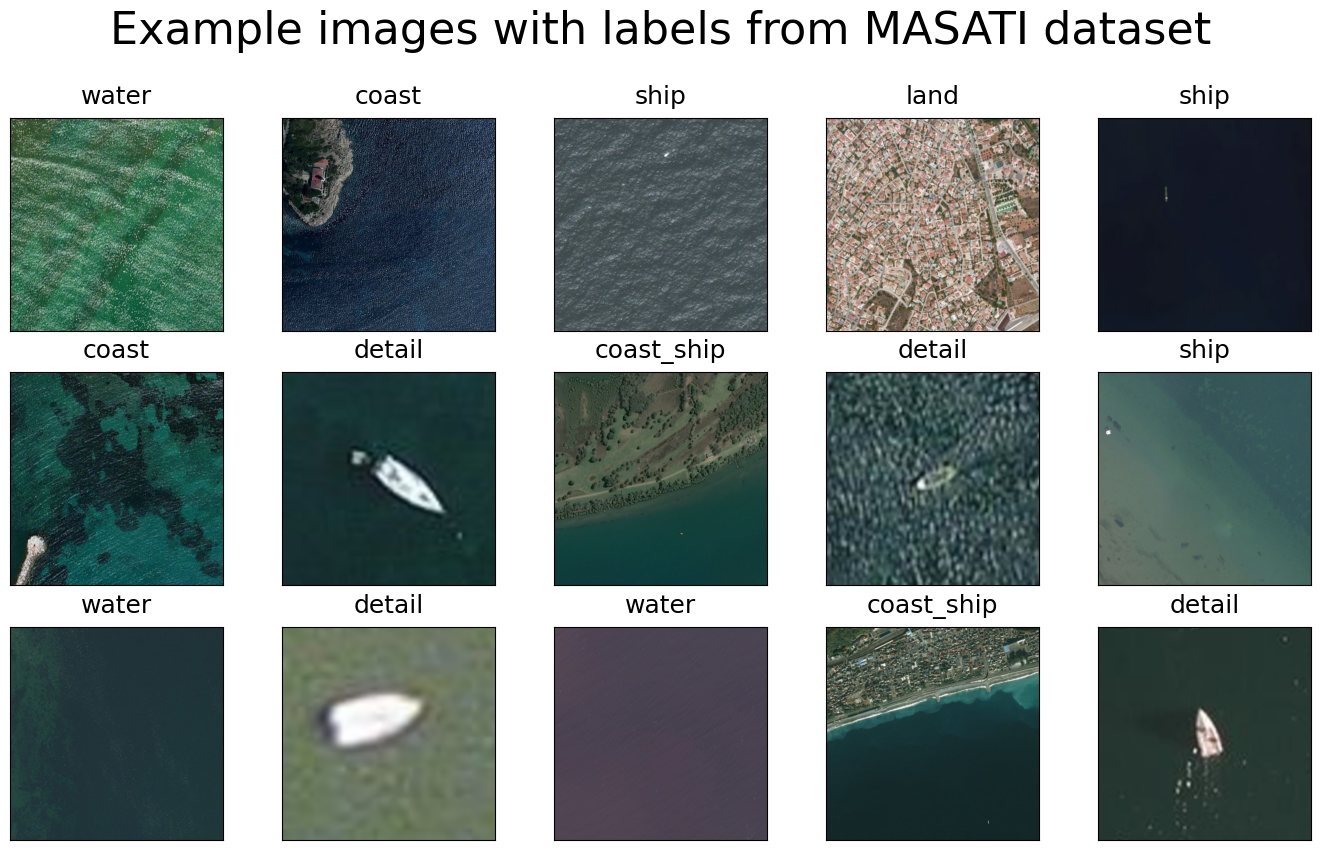

In [22]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [23]:
dataset.show_samples()

,File name,Label
0,land/l0673.png,land
1,water/w0894.png,water
2,water/w0227.png,water
3,land/l0393.png,land
4,water/w0449.png,water
5,land/l0314.png,land
6,coast_ship/x0864.png,coast_ship
7,ship/s0032.png,ship
8,coast/c0908.png,coast
9,detail/d1649.png,detail


In [25]:
dataset.data_distribution_table()

,Label,Count
0,coast,905
1,coast_ship,845
2,detail,1429
3,land,864
4,multi,231
5,ship,802
6,water,813


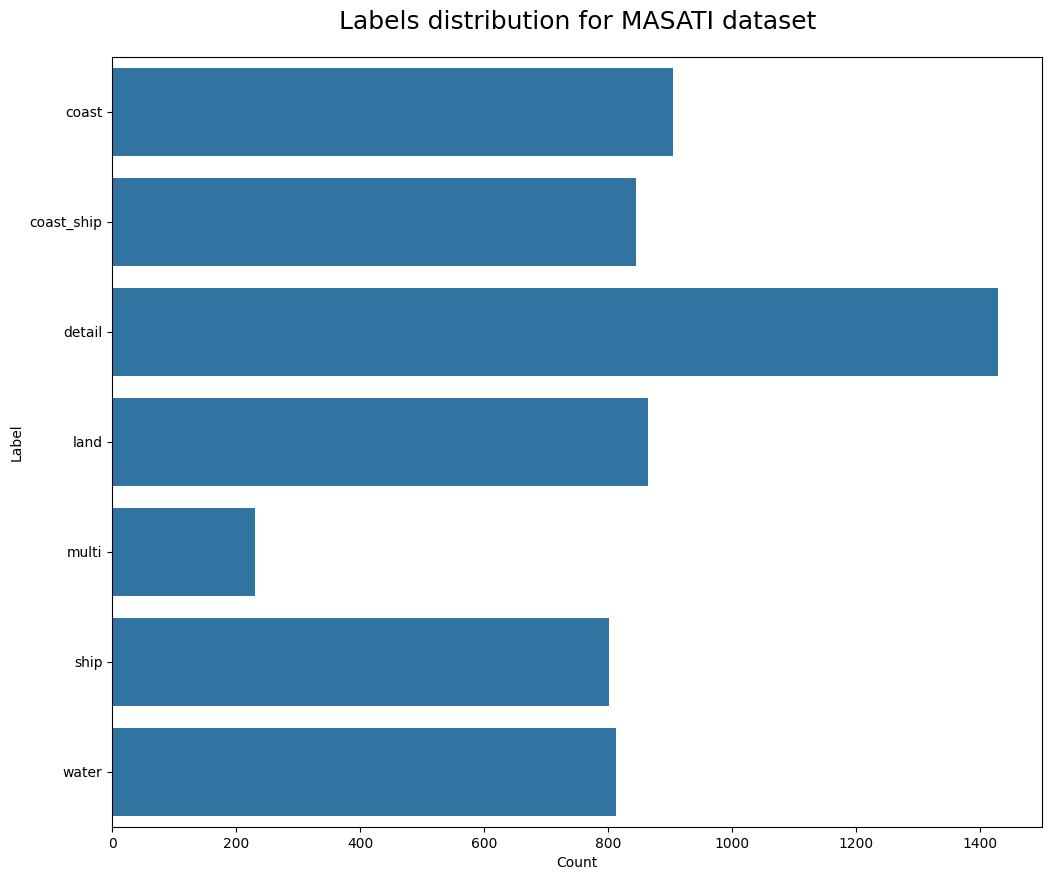

In [26]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/MASATI/image_classification/",
    "csv_file": "./data/MASATI/image_classification/train.csv",
     "transforms": ["aitlas.transforms.ResizeToTensor"]
}

train_dataset = MASATIImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/MASATI/image_classification/",
    "csv_file": "./data/MASATI/image_classification/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = MASATIImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(5889, 736)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/MASATI/image_classification/"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 07:49:14,263 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 07:49:14,389 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [29]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 07:49:15,820 INFO Starting training.
training: 100%|██████████| 185/185 [00:47<00:00,  3.92it/s]
2025-05-20 07:50:03,047 INFO epoch: 1, time: 48, loss:  0.50824
testing on train set: 100%|██████████| 185/185 [00:16<00:00, 11.25it/s]
2025-05-20 07:50:21,269 INFO Accuracy:0.9281711665817626, Precision Micro:0.9281711665817626, Precision Macro:0.9188026598390593, Precision Weighted:0.9317178465697388, Precision per Class:[0.9696288  0.83660131 0.91922006 0.86877828 0.97820163 1.
 0.85918854], Recall Micro:0.9281711665817626, Recall Macro:0.9099238879674179, Recall Weighted:0.9281711665817627, Recall per Class:[0.99768519 0.99005525 0.82294264 0.83116883 0.84970414 0.99230231
 0.88560886], F1_score Micro:0.928171166581762, F1_score Macro:0.9122984857467753, F1_score Weighted:0.927866698740615, F1_score per Class:[0.98345693 0.90688259 0.86842105 0.84955752 0.90943635 0.99613628
 0.87219867]
testing on validation set: 100%|██████████| 23/23 [00:02<00:00,  9.15it/s]
2025-05-20 07:

0.05457183139945542

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/MASATI/image_classification/",
    "csv_file": "./data/MASATI/image_classification/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = MASATIImageClassificationDataset(test_dataset_config)
model_path = "./data/experiments/MASATI/image_classification/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 08:14:34,659 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MASATI/image_classification/checkpoint.pth.tar
2025-05-20 08:14:34,883 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MASATI/image_classification/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 46/46 [00:02<00:00, 17.24it/s]


[{'Accuracy': 0.9538043478260869},
 {'Precision Micro': 0.9538043478260869,
  'Precision Macro': 0.9397886868137724,
  'Precision Weighted': 0.9539404578137893,
  'Precision per Class': array([0.98      , 0.99152542, 0.86363636, 0.875     , 0.94565217,
         0.99487179, 0.92783505])},
 {'Recall Micro': 0.9538043478260869,
  'Recall Macro': 0.9294401723953305,
  'Recall Weighted': 0.953804347826087,
  'Recall per Class': array([1.        , 0.96694215, 0.89622642, 0.77777778, 0.95604396,
         1.        , 0.90909091])},
 {'F1_score Micro': 0.9538043478260864,
  'F1_score Macro': 0.9341076934548275,
  'F1_score Weighted': 0.9536671168115043,
  'F1_score per Class': array([0.98989899, 0.9790795 , 0.87962963, 0.82352941, 0.95081967,
         0.99742931, 0.91836735])}]

## Predictions

2025-05-20 08:15:48,860 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MASATI/image_classification/checkpoint.pth.tar
2025-05-20 08:15:49,367 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MASATI/image_classification/checkpoint.pth.tar at epoch 21


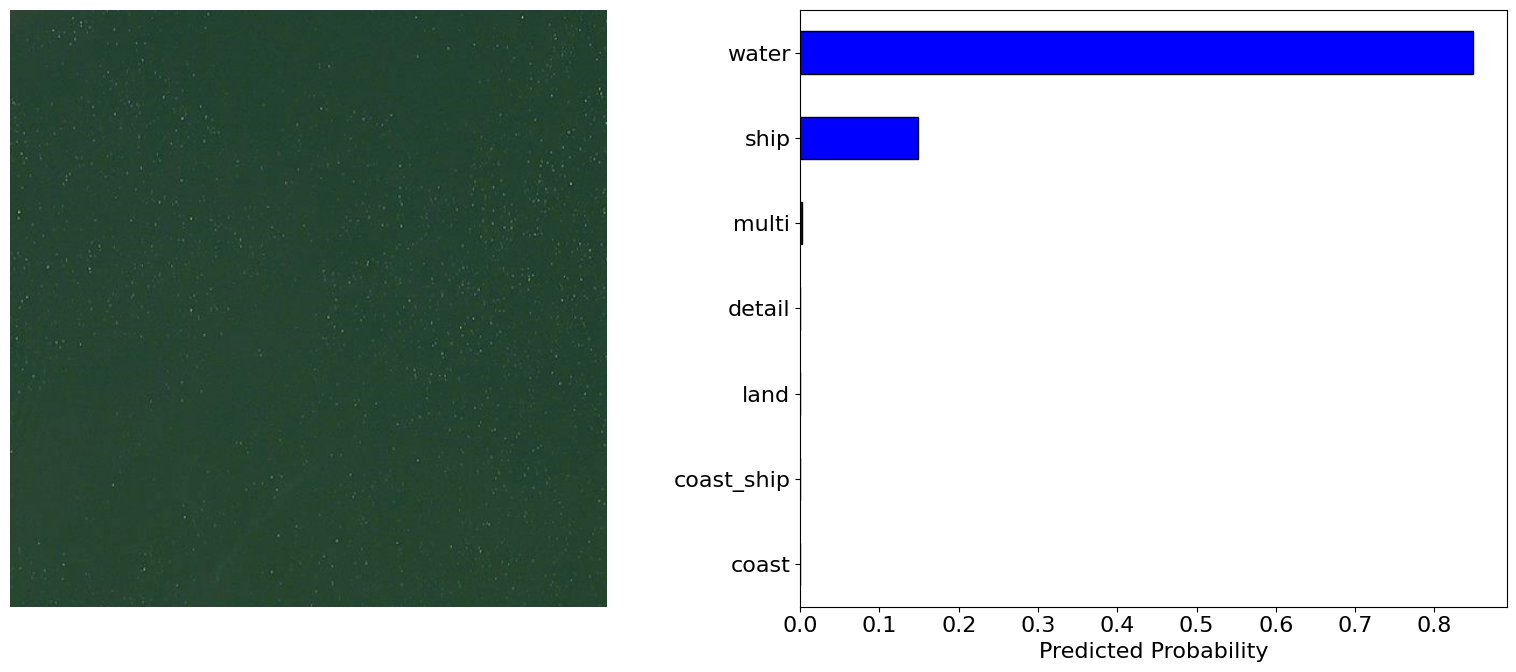

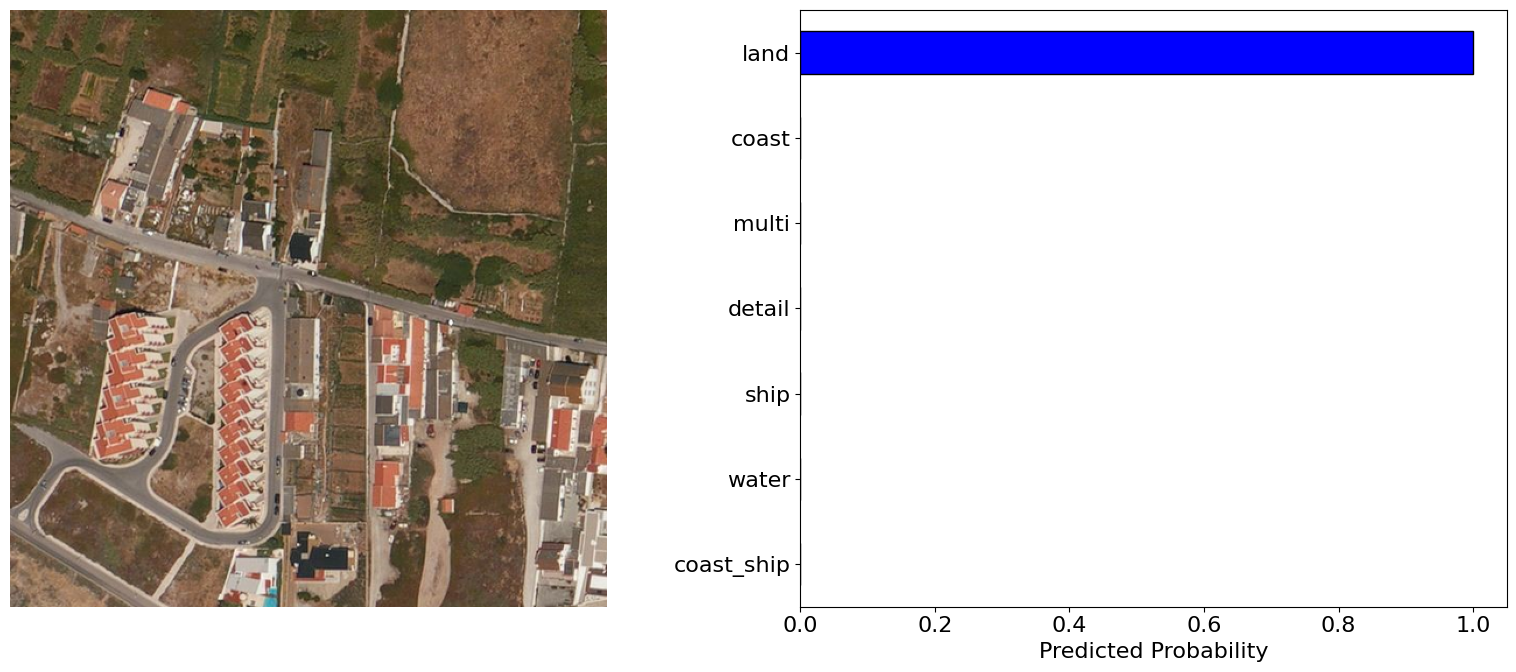

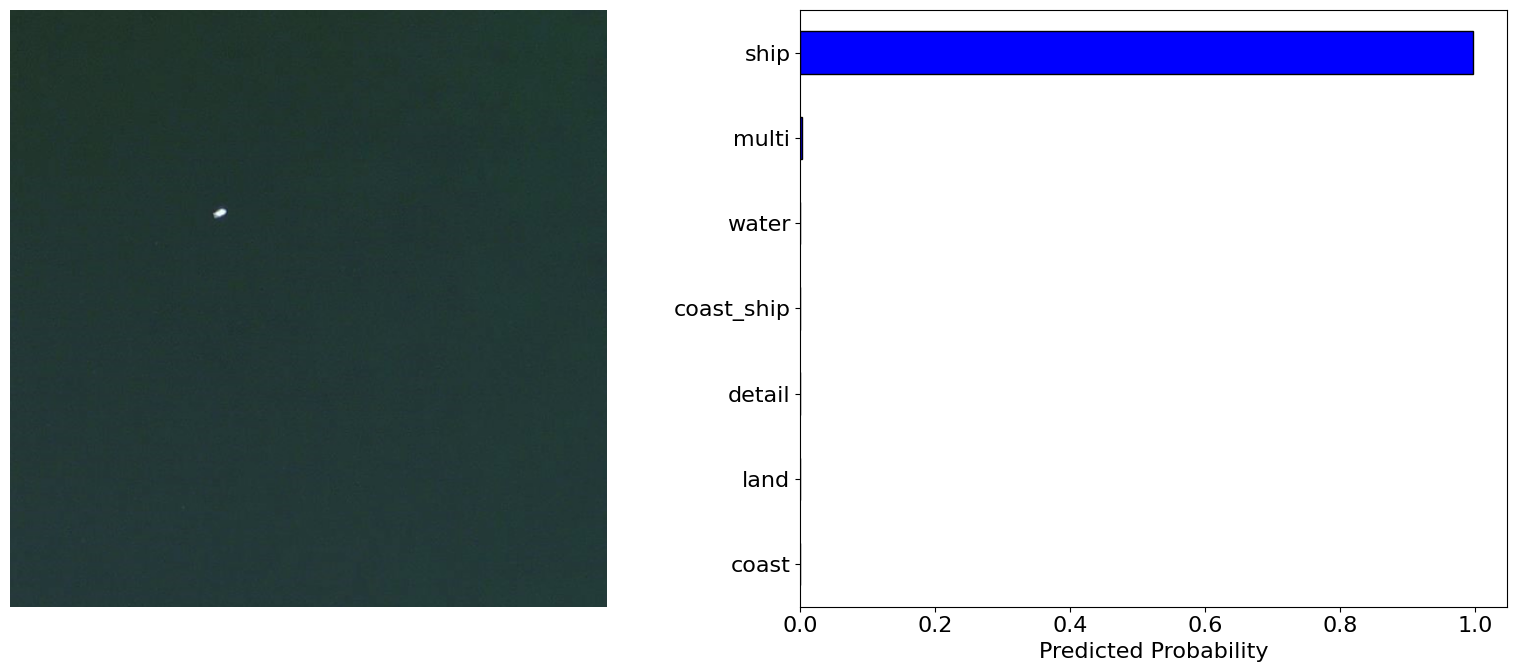

In [ ]:
labels = ["land","coast","ship","multi","coast_ship","detail","water"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/MASATI/image_classification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/MASATI/image_classification/water/w0049.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/MASATI/image_classification/land/l0173.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/MASATI/image_classification/ship/s1013.png')
fig = model.predict_image(image, labels, transform)